# Попробуем обучить модель явно выдавать цепочки рассуждений в решении задач

Основной путь: NVIDIA, Python 3.11, Qwen2.5-1.5B-Instruct и 512 готовых диалогов. Проходим ячейки по порядку в чистом ядре. Установка выполняется один раз, после неё перезапускаем ядро. Контрольный вопрос не содержит инструкции о стиле.

In [1]:
import torch

print("PyTorch:", torch.__version__)
assert torch.cuda.is_available(), "CUDA недоступна: см. раздел помощи"
print("Видеокарта:", torch.cuda.get_device_name(0))

PyTorch: 2.5.1+cu121
Видеокарта: NVIDIA RTX 4500 Ada Generation


## Возьмем модель с большим числом параметром 
В качестве модели используем Qwen2.5-3.B-Instruct

In [2]:
model_id = "Qwen/Qwen2.5-3B-Instruct"

In [3]:
from transformers import pipeline

chat = pipeline(
    "text-generation", model=model_id, device=0, dtype="auto"
)

/mnt/projects/llm_fine-tuning/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading checkpoint shards: 100%|██████████████████████████████| 2/2 [00:00<00:00, 37.28it/s]
Device set to use cuda:0


## Подготовим список задач для модели

role="user" обозначает пользователя, content содержит вопрос. Pipeline сам оформляет диалог для Qwen. max_new_tokens ограничивает продолжение 100 токенами, do_sample=False отключает случайную выборку. Из результата берём первый диалог и последнее сообщение — ответ помощника. Теперь ask("вопрос") вызывается одной строкой. before сохраняет исходный ответ.

In [4]:
import json

with open("../data/cot_validation_set_bilingual.json", "r", encoding="utf-8") as file:
    tasks = json.load(file)['questions']

## Примеры задач

In [5]:
print("Задача 1")
print(tasks[0]['question'])
for i, step in enumerate(tasks[0]['reference_steps']):
    print(f"Шаг {i}: {step}")
print(tasks[0]['reference_answer'])

Задача 1
A train travels at 90 km/h. How many meters does it cover in 1 second?
Шаг 0: 90 km/h = 90000 m / 3600 s
Шаг 1: 90000 / 3600 = 25
Шаг 2: So the train covers 25 m per second
25


In [6]:
print("Задача 2")
print(tasks[1]['question'])
for i, step in enumerate(tasks[1]['reference_steps']):
    print(f"Шаг {i}: {step}")
print(tasks[1]['reference_answer'])

Задача 2
A store offers a 20% discount on all items, and then an extra coupon takes another 10% off the final price. Is the total discount bigger or smaller than 30%?
Шаг 0: First discount: price becomes 0.8 of the original
Шаг 1: Second discount applies to the new price: 0.8 * 0.9 = 0.72
Шаг 2: Total discount is 1 - 0.72 = 0.28, i.e. 28%
Шаг 3: 28% < 30%, so the total discount is smaller
28% (smaller than 30%)


In [7]:
def ask(question):
    reply = chat(
        [{"role": "user", "content": question}],
        max_new_tokens=1024, do_sample=False
    )
    return reply[0]["generated_text"][-1]["content"]

## Зададим вопросы базовой модели

In [8]:
for task in tasks:
    task["before"] = ask(task["question"])

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


## Возьмём готовые диалоги

load_dataset открывает набор как таблицу. train — имя раздела, а не команда начала обучения. В каждой строке messages — реплики. Фильтр оставляет короткие вопросы, select берёт первые 512 подходящих строк. Ответы не переписываются, стиль не добавляется вручную.

In [9]:
from datasets import load_dataset

# В наборе уже есть вопросы и ответы в пиратском стиле.
data = load_dataset("open-thoughts/OpenThoughts-114k", split="train")
# data[0]
# Возьмём 512 примеров с вопросами короче 300 символов.
# data = data.filter(lambda row: len(row["messages"][0]["content"]) < 300)
data = data.select(range(512))
# print(data[0])

## Добавим обучаемую часть

PEFT — библиотека экономного дообучения. LoRA добавляет небольшие обучаемые матрицы к преобразованиям модели. CAUSAL_LM обозначает предсказание следующего токена по предыдущим. Стандартная конфигурация PEFT для Qwen выбирает поддерживаемые слои; базовые веса остаются замороженными.

In [10]:
from peft import LoraConfig

# Для первого опыта используем стандартные настройки LoRA.
adapter = LoraConfig(task_type="CAUSAL_LM")

## Зададим размер эксперимента

SFT — обучение на примерах желаемого поведения. Здесь: 400 обновлений; learning_rate=0.0003 задаёт масштаб изменения; по 2 диалога обрабатываются за проход, 4 прохода накапливаются перед обновлением. Это 8 примеров на шаг. max_length ограничивает диалог 384 токенами, длинный хвост обрезается. output_dir — папка результатов, report_to="none" отключает внешние сервисы журналирования. Остальные параметры берутся из выбранной версии TRL.

In [11]:
from trl import SFTConfig, SFTTrainer

settings = SFTConfig(
    output_dir="../outputs/chain-of-thoughts-output",
    max_steps=400, learning_rate=3e-4,
    per_device_train_batch_size=2, gradient_accumulation_steps=4,
    max_length=384,
    report_to="none"
)

## Запустим дообучение

Передаём загруженную модель, её токенизатор, диалоги, LoRA и настройки. SFTTrainer готовит последовательности, собирает порции данных, вычисляет ошибку и обновляет параметры адаптера. train() запускает цикл. Прогресс появляется в выводе ячейки; loss — ошибка предсказания токенов, а не доля правильных ответов.

In [12]:
trainer = SFTTrainer(
    model=chat.model, processing_class=chat.tokenizer,
    train_dataset=data, peft_config=adapter, args=settings
)
trainer.train()

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151643}.


Step,Training Loss
10,1.689600
20,1.124900
30,0.757100
40,0.641300
50,0.493200
60,0.633000
70,0.563700
80,0.397400
90,0.442700
100,0.461700


TrainOutput(global_step=400, training_loss=0.5031550794839859, metrics={'train_runtime': 379.3069, 'train_samples_per_second': 8.436, 'train_steps_per_second': 1.055, 'total_flos': 2.0471441522688e+16, 'train_loss': 0.5031550794839859, 'epoch': 6.25})

## Посмотрим на ход обучения

В log_history есть измерения loss и итоговая статистика. Берём записи с loss и печатаем шаг и усреднённую ошибку. График в лекции строится по такому журналу реального запуска; учебная анимация показана отдельно.

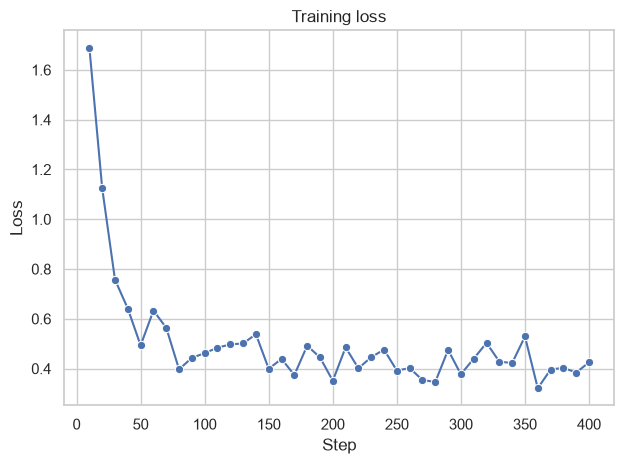

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

step = []
loss = []

for row in trainer.state.log_history:
    if "loss" in row:
        step.append(row["step"])
        loss.append(round(row["loss"], 3))

sns.set_theme(style="whitegrid")

sns.lineplot(x=step, y=loss, marker="o")

plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training loss")
plt.tight_layout()
plt.show()

## Повторим тот же вопрос

trainer.model содержит базу с адаптером. eval() включает режим использования. Вопрос и настройки генерации не меняются, инструкции «говори как пират» нет. Сравниваем сохранённый before с after.

In [14]:
# Подключаем обученный адаптер к тому же генератору.
chat.model = trainer.model
chat.model.eval()

for i, task in enumerate(tasks):
    task["after"] = ask(task["question"])
    print(f"Задача {i + 1}: {task['question']}")
    print("ДО:\n", task["before"])
    print("ПОСЛЕ:\n", task["after"])
    print("#" * 100)

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Задача 1: A train travels at 90 km/h. How many meters does it cover in 1 second?
ДО:
 To determine how many meters the train covers in 1 second when traveling at 90 km/h, we need to convert the speed from kilometers per hour (km/h) to meters per second (m/s).

First, let's recall the conversion factors:
- 1 kilometer (km) = 1000 meters (m)
- 1 hour (h) = 3600 seconds (s)

Given that the train's speed is 90 km/h, we can convert this speed to meters per second as follows:

\[ 90 \text{ km/h} = 90 \times \frac{1000 \text{ m}}{1 \text{ km}} \times \frac{1 \text{ h}}{3600 \text{ s}} \]

Now, perform the multiplication and division:

\[ 90 \times \frac{1000}{3600} = 90 \times \frac{10}{36} = 90 \times \frac{5}{18} = 5 \times 5 = 25 \text{ m/s} \]

So, the train covers 25 meters in 1 second.
ПОСЛЕ:
 To determine how many meters the train covers in 1 second when traveling at 90 km/h, we need to convert the speed from kilometers per hour (km/h) to meters per second (m/s).

First, recall the con

## Сохраним результат

В pirate-adapter записываются веса LoRA, конфигурация и токенизатор. Базовая модель не копируется: при следующем запуске нужны и база, и адаптер. База уже находится в локальном кэше. Отдельный блокнот показывает загрузку в новом сеансе.

In [15]:
trainer.save_model("../adapters/chains-of-thoughts-adapter")
chat.tokenizer.save_pretrained("../adapters/chains-of-thoughts-adapter")

('../adapters/chains-of-thoughts-adapter/tokenizer_config.json',
 '../adapters/chains-of-thoughts-adapter/special_tokens_map.json',
 '../adapters/chains-of-thoughts-adapter/chat_template.jinja',
 '../adapters/chains-of-thoughts-adapter/vocab.json',
 '../adapters/chains-of-thoughts-adapter/merges.txt',
 '../adapters/chains-of-thoughts-adapter/added_tokens.json',
 '../adapters/chains-of-thoughts-adapter/tokenizer.json')

In [16]:
with open("../data/cot_validation_set_bilingual_out.json", "w", encoding="utf-8") as file:
    json.dump(tasks, file, indent=4, ensure_ascii=False)